# Demand-Side Management: Rockafellian + CVaR-CC
## Framework completo paso a paso

**Problema:** Retailer de electricidad disena tarifas TOU (24h) bajo respuesta
estocastica de consumidores. Maximizar profit sujeto a que la carga no exceda
la capacidad del transformador con probabilidad >= 90%.

**Correccion clave del modelo:** Capacidad FIJA del transformador (MW), no
proporcional a la demanda. Con capacidad proporcional, TOU no afecta reliability.

**5 Escenarios:**
1. **Red holgada** (Dbar=130, beta=0.25): Facil, gap grande
2. **Red moderada** (Dbar=122, beta=0.25): Caso tipico
3. **Baja elasticidad** (Dbar=125, beta=0.15): Consumidores rigidos
4. **Caso del bug** (Dbar=115, beta=0.40): Descubrimiento t_hi > u*
5. **Infactible** (Dbar=112, beta=0.15): CC infactible


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

N_OPT = 1000
N_MC = 2000
ALPHA = 0.10
GAMMA_PATH = [10**k for k in [2.0, 2.6, 3.2, 3.8, 4.4, 5.0]]

C_CVAR = '#2196F3'
C_CC = '#F44336'
C_MC = '#4CAF50'
C_TGT = '#000000'

print("Configuracion:")
print(f"  N_OPT = {N_OPT}, N_MC = {N_MC}, alpha = {ALPHA}")


Configuracion:
  N_OPT = 1000, N_MC = 2000, alpha = 0.1


In [49]:
def solve_rockafellian_multistart(gamma, D0, beta_arr, Dbar, t_val, p_ref=None, n_starts=5):
    """
    Resuelve el Rockafellian desde multiples puntos iniciales.
    Retorna la mejor solucion encontrada.
    """
    bounds = [(P_MIN, P_MAX)] * T
    best_obj = np.inf
    best_p = None

    starts = []
    # Start 1: referencia (warm start de solucion anterior)
    if p_ref is not None:
        starts.append(p_ref.copy())
    # Start 2: tarifa plana alta (maximiza revenue)
    starts.append(np.full(T, 90.0))
    # Start 3: TOU agresivo
    starts.append(np.clip(70 + 40*np.sin(np.pi*(hours-6)/12), P_MIN, P_MAX))
    # Start 4: precios altos en peak, bajos off-peak
    starts.append(np.where(base_profile > 90, 110, 50).astype(float))
    # Start 5: tarifa plana media
    starts.append(np.full(T, 70.0))
    # Start 6: random
    np.random.seed(None)  # no fijar para variabilidad
    starts.append(np.random.uniform(P_MIN, P_MAX, T))

    for p0 in starts[:n_starts]:
        res = minimize(rockafellian_obj_dsm, p0,
                       args=(gamma, D0, beta_arr, Dbar, t_val),
                       method='L-BFGS-B', bounds=bounds,
                       options={'maxiter': 5000, 'ftol': 1e-14})
        if res.fun < best_obj:
            best_obj = res.fun
            best_p = res.x.copy()

    return best_p


## 1. El Problema

### DSM con Time-of-Use Pricing y Chance Constraint

Un retailer de electricidad disena precios horarios $p_t \in [20, 120]$ \$/MWh
para 24 horas. Los consumidores responden a los precios desplazando carga:

$$D_t(p,\xi) = D^0_t(\xi) - \beta(\xi) \cdot D^0_t(\xi) \cdot \frac{p_t - \bar{p}}{\bar{p}}$$

donde $D^0_t$ es la demanda base, $\beta$ es la elasticidad estocastica, y
$\bar{p} = \frac{1}{24}\sum_t p_t$ es el precio promedio diario.

**Restriccion:** La carga no debe exceder la capacidad del transformador $\bar{D}$
en NINGUNA hora, con probabilidad >= 90%:
$$\mathbb{P}\left(\max_t (D_t(p,\xi) - \bar{D}) \le 0\right) \ge 1 - \alpha$$

**Funcion de perdida:** $L(p,\xi) = \max_t (D_t(p,\xi) - \bar{D})$

**Objetivo:** Maximizar profit $\sum_t (p_t - c_w) \cdot \mathbb{E}[D_t(p,\xi)]$

### Correccion del modelo: capacidad FIJA vs proporcional

El modelo original usaba $\bar{D}_t = \text{factor} \times \mu_t$ (proporcional).
Con eso, TOU NO afecta reliability porque mover carga de peak a off-peak
tambien mueve la referencia. El modelo corregido usa $\bar{D}$ FIJO (MW),
donde off-peak tiene headroom y el load shifting es efectivo.


PARAMETROS DSM
  Periodos T = 24 horas
  Precios p_t in [20.0, 120.0] $/MWh
  Costo wholesale = $30.0/MWh
  Demanda base peak 1 = 115 MW (hora 9)
  Demanda base peak 2 = 105 MW (hora 18)
  Demanda base min = 55 MW
  Demanda base media = 88 MW



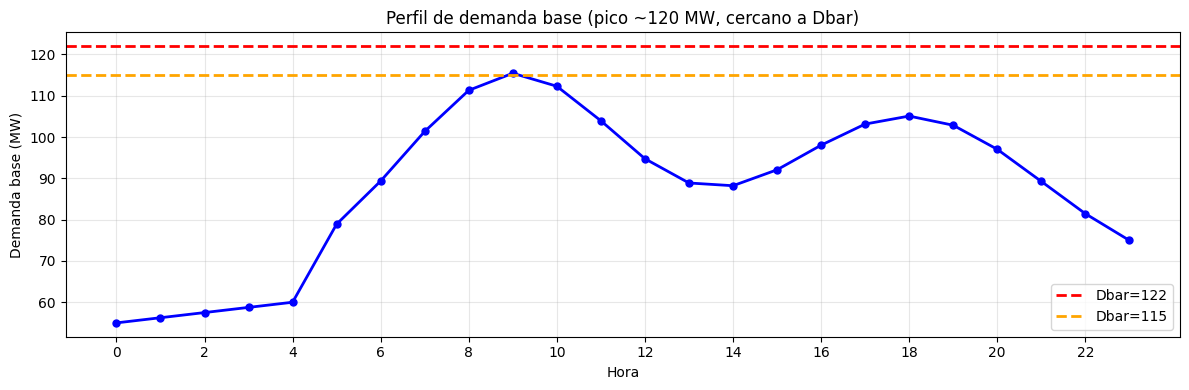

ESCENARIOS
  1. Moderada: Dbar=122MW, beta=0.25, Headroom ~2MW
  2. Ajustada: Dbar=118MW, beta=0.25, Pico > Dbar
  3. Baja elasticidad: Dbar=120MW, beta=0.15, Consumidores rigidos
  4. Caso del bug: Dbar=115MW, beta=0.4, t_hi > u*
  5. Infactible: Dbar=112MW, beta=0.15, CC imposible


In [50]:
T = 24
P_MIN, P_MAX = 20.0, 120.0
C_WHOLESALE = 30.0

# CAMBIO 1: perfil con pico mas alto (~120 MW en vez de ~114)
hours = np.arange(T)
base_profile = 65 + 50*np.exp(-0.5*((hours-9)/2.5)**2) + 40*np.exp(-0.5*((hours-18)/3)**2)
base_profile[:5] = np.linspace(55, 60, 5)

print("PARAMETROS DSM")
print("=" * 60)
print(f"  Periodos T = {T} horas")
print(f"  Precios p_t in [{P_MIN}, {P_MAX}] $/MWh")
print(f"  Costo wholesale = ${C_WHOLESALE}/MWh")
print(f"  Demanda base peak 1 = {base_profile[9]:.0f} MW (hora 9)")
print(f"  Demanda base peak 2 = {base_profile[18]:.0f} MW (hora 18)")
print(f"  Demanda base min = {base_profile.min():.0f} MW")
print(f"  Demanda base media = {base_profile.mean():.0f} MW")
print()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(hours, base_profile, 'b-o', lw=2, ms=5)
ax.axhline(y=122, color='red', ls='--', lw=2, label='Dbar=122')
ax.axhline(y=115, color='orange', ls='--', lw=2, label='Dbar=115')
ax.set_xlabel('Hora'); ax.set_ylabel('Demanda base (MW)')
ax.set_title('Perfil de demanda base (pico ~120 MW, cercano a Dbar)')
ax.legend(); ax.grid(True, alpha=0.3); ax.set_xticks(range(0,24,2))
plt.tight_layout(); plt.show()

# CAMBIO 2: escenarios con Dbar mas ajustados
scenarios = [
    {'name': '1. Moderada',        'Dbar': 122, 'beta_mean': 0.25, 'desc': 'Headroom ~2MW'},
    {'name': '2. Ajustada',        'Dbar': 118, 'beta_mean': 0.25, 'desc': 'Pico > Dbar'},
    {'name': '3. Baja elasticidad','Dbar': 120, 'beta_mean': 0.15, 'desc': 'Consumidores rigidos'},
    {'name': '4. Caso del bug',    'Dbar': 115, 'beta_mean': 0.40, 'desc': 't_hi > u*'},
    {'name': '5. Infactible',      'Dbar': 112, 'beta_mean': 0.15, 'desc': 'CC imposible'},
]

print("ESCENARIOS")
print("=" * 60)
for s in scenarios:
    print(f"  {s['name']}: Dbar={s['Dbar']}MW, beta={s['beta_mean']}, {s['desc']}")


In [51]:
def generate_dsm_scenarios(beta_mean, N, seed=42):
    np.random.seed(seed)
    # Demanda base con ruido ~10%
    D0 = np.random.lognormal(
        mean=np.log(base_profile[None, :]),
        sigma=0.10, size=(N, T))
    # Elasticidad estocastica ~ Beta(3,3) escalada
    beta = np.random.beta(3, 3, size=N) * (2 * beta_mean)
    return D0, beta

D0_opt, beta_opt = generate_dsm_scenarios(0.25, N_OPT, seed=42)
D0_mc, beta_mc = generate_dsm_scenarios(0.25, N_MC, seed=123)

print("Escenarios generados (beta=0.25):")
print(f"  Opt: D0 {D0_opt.shape}, beta {beta_opt.shape}")
print(f"  MC:  D0 {D0_mc.shape}, beta {beta_mc.shape}")
print(f"  D0 media peak (h9): {D0_opt[:,9].mean():.1f} MW")
print(f"  Beta: media={beta_opt.mean():.3f}, std={beta_opt.std():.3f}")
print(f"  Beta: min={beta_opt.min():.3f}, max={beta_opt.max():.3f}")


Escenarios generados (beta=0.25):
  Opt: D0 (1000, 24), beta (1000,)
  MC:  D0 (2000, 24), beta (2000,)
  D0 media peak (h9): 116.0 MW
  Beta: media=0.257, std=0.095
  Beta: min=0.011, max=0.485


In [52]:
def compute_demand(prices, D0, beta):
    """Calcula demanda D_t(p,xi) para cada escenario."""
    N = D0.shape[0]
    p_bar = np.mean(prices)
    if p_bar < 1e-6: p_bar = 1.0
    price_effect = (prices[None, :] - p_bar) / p_bar  # (1, T)
    D = D0 - beta[:, None] * D0 * price_effect  # (N, T)
    return np.maximum(D, 0)  # no negativa

def compute_loss_dsm(prices, D0, beta, Dbar):
    """L = max_t (D_t - Dbar). Negativo = margen, positivo = violacion."""
    D = compute_demand(prices, D0, beta)
    return np.max(D - Dbar, axis=1)  # (N,)

def compute_profit(prices, D0, beta):
    """Profit = sum_t (p_t - c_w) * E[D_t]"""
    D = compute_demand(prices, D0, beta)
    D_mean = D.mean(axis=0)
    return np.sum((prices - C_WHOLESALE) * D_mean)

def compute_cvar(L, alpha):
    N = len(L)
    sorted_L = np.sort(L)
    idx = min(int(np.ceil((1 - alpha) * N)) - 1, N - 1)
    var = sorted_L[max(idx, 0)]
    cvar = var + (1.0 / alpha) * np.mean(np.maximum(L - var, 0.0))
    return cvar, var

def compute_bpoe(L, tol=0.001):
    a_lo, a_hi = 0.001, 0.999
    for _ in range(60):
        a_mid = (a_lo + a_hi) / 2
        c, _ = compute_cvar(L, a_mid)
        if c <= 0: a_hi = a_mid
        else: a_lo = a_mid
        if a_hi - a_lo < tol: break
    return (a_lo + a_hi) / 2

# Test con tarifa plana
p_flat = np.full(T, 70.0)
L_test = compute_loss_dsm(p_flat, D0_opt, beta_opt, 122)
print("Test tarifa plana $70/MWh, Dbar=122:")
print(f"  Profit = ${compute_profit(p_flat, D0_opt, beta_opt):.0f}")
print(f"  P(L>0) = {np.mean(L_test > 0):.3f}")
cvar_t, var_t = compute_cvar(L_test, ALPHA)
print(f"  CVaR = {cvar_t:.2f}, VaR = {var_t:.2f}")
print(f"  L: min={L_test.min():.1f}, med={np.median(L_test):.1f}, max={L_test.max():.1f}")


Test tarifa plana $70/MWh, Dbar=122:
  Profit = $85064
  P(L>0) = 0.662
  CVaR = 19.49, VaR = 14.47
  L: min=-14.3, med=3.2, max=35.4


## 2. Entender el modelo: efecto del TOU pricing

Antes de optimizar, veamos como los precios afectan la demanda y las violaciones.


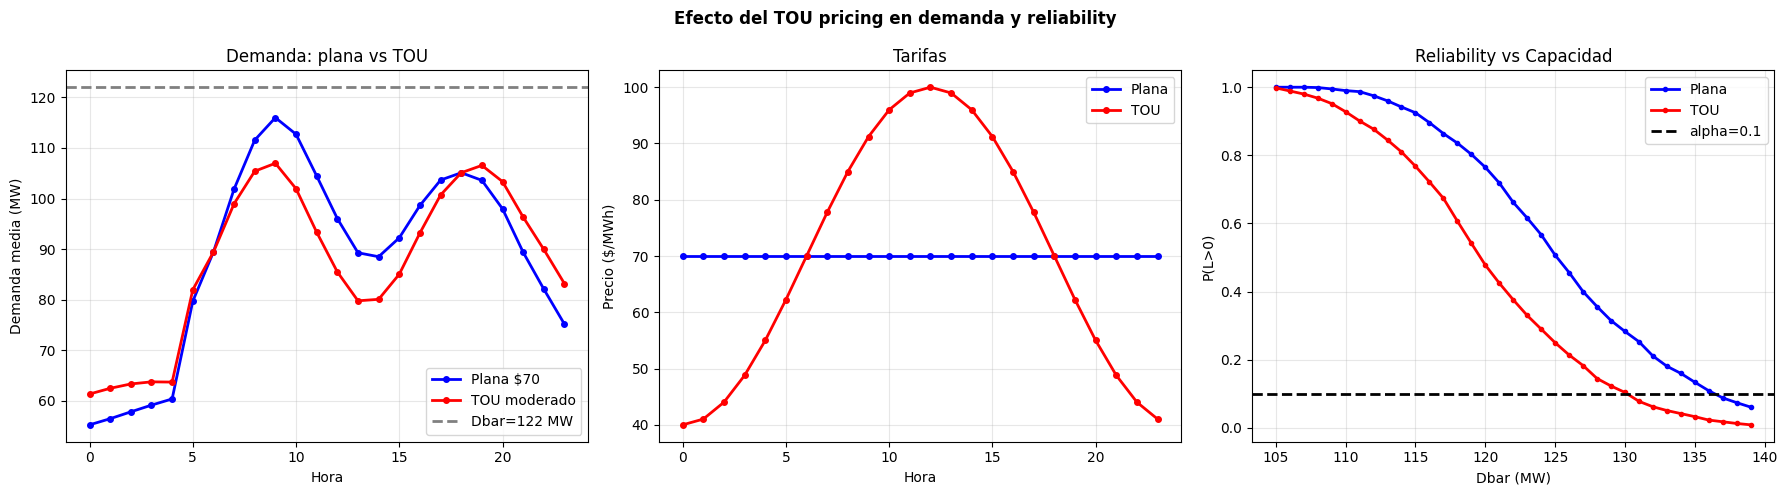

TOU reduce el pico de demanda desplazando carga a off-peak
Con Dbar fijo, esto REDUCE la probabilidad de violacion


In [53]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Tarifa plana vs TOU
p_flat = np.full(T, 70.0)
p_tou = 70 + 30*np.sin(np.pi*(hours-6)/12)
p_tou = np.clip(p_tou, P_MIN, P_MAX)

for i, (name, prices, color) in enumerate([
    ('Plana $70', p_flat, 'blue'),
    ('TOU moderado', p_tou, 'red')
]):
    D = compute_demand(prices, D0_opt, beta_opt)
    ax = axes[0] if i == 0 else axes[0]
    ax.plot(hours, D.mean(axis=0), '-o', ms=4, lw=2, color=color, label=f'{name}')

axes[0].axhline(y=122, color='gray', ls='--', lw=2, label='Dbar=122 MW')
axes[0].set_xlabel('Hora'); axes[0].set_ylabel('Demanda media (MW)')
axes[0].set_title('Demanda: plana vs TOU')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(hours, p_flat, '-o', ms=4, lw=2, color='blue', label='Plana')
axes[1].plot(hours, p_tou, '-o', ms=4, lw=2, color='red', label='TOU')
axes[1].set_xlabel('Hora'); axes[1].set_ylabel('Precio ($/MWh)')
axes[1].set_title('Tarifas'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

# P(L>0) vs Dbar para ambas tarifas
dbars = np.arange(105, 140)
p_flat_ps = [np.mean(compute_loss_dsm(p_flat, D0_opt, beta_opt, d) > 0) for d in dbars]
p_tou_ps = [np.mean(compute_loss_dsm(p_tou, D0_opt, beta_opt, d) > 0) for d in dbars]
axes[2].plot(dbars, p_flat_ps, 'b-o', ms=3, lw=2, label='Plana')
axes[2].plot(dbars, p_tou_ps, 'r-o', ms=3, lw=2, label='TOU')
axes[2].axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
axes[2].set_xlabel('Dbar (MW)'); axes[2].set_ylabel('P(L>0)')
axes[2].set_title('Reliability vs Capacidad')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Efecto del TOU pricing en demanda y reliability', fontweight='bold')
plt.tight_layout(); plt.show()
print("TOU reduce el pico de demanda desplazando carga a off-peak")
print("Con Dbar fijo, esto REDUCE la probabilidad de violacion")


## 3. Mapa de controlabilidad (beta, Dbar)

No todas las combinaciones de elasticidad y capacidad permiten satisfacer la CC.
Mapeamos sistematicamente que combinaciones son factibles.


In [54]:
def find_best_P(Dbar, beta_mean, D0, beta_arr):
    """Encuentra la mejor P(L>0) alcanzable optimizando precios."""
    def neg_reliability(p):
        L = compute_loss_dsm(p, D0, beta_arr, Dbar)
        return np.mean(L > 0)

    best_P = 1.0
    # Probar varias tarifas iniciales
    for trial in range(5):
        if trial == 0: p0 = np.full(T, 70.0)
        elif trial == 1: p0 = 70 + 40*np.sin(np.pi*(hours-6)/12)
        elif trial == 2: p0 = np.where(base_profile > 100, 110, 50)
        elif trial == 3: p0 = np.full(T, 90.0)
        else: p0 = np.random.uniform(P_MIN, P_MAX, T)
        p0 = np.clip(p0, P_MIN, P_MAX)

        res = minimize(neg_reliability, p0, method='L-BFGS-B',
                       bounds=[(P_MIN, P_MAX)]*T,
                       options={'maxiter': 1000, 'ftol': 1e-12})
        best_P = min(best_P, res.fun)
    return best_P

betas_map = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
dbars_map = [112, 115, 118, 120, 122, 125, 130]

print("MAPA DE CONTROLABILIDAD: P_best(beta, Dbar)")
print("=" * 75)
print(f"{'Dbar':>6}", end='')
for b in betas_map:
    print(f"  beta={b:.2f}", end='')
print()
print("-" * 75)

ctrl_map = {}
for Dbar in dbars_map:
    print(f"{Dbar:>6}", end='')
    for bm in betas_map:
        D0_tmp, beta_tmp = generate_dsm_scenarios(bm, N_OPT, seed=42)
        p_best = find_best_P(Dbar, bm, D0_tmp, beta_tmp)
        ctrl_map[(Dbar, bm)] = p_best
        marker = ' *' if p_best <= ALPHA else '  '
        print(f"    {p_best:.3f}{marker}", end='')
    print()
print()
print("* = CC factible (P_best <= 0.10)")
print("La frontera de factibilidad es diagonal: mas beta O mas Dbar -> factible")


MAPA DE CONTROLABILIDAD: P_best(beta, Dbar)
  Dbar  beta=0.10  beta=0.15  beta=0.20  beta=0.25  beta=0.30  beta=0.40
---------------------------------------------------------------------------
   112    0.867      0.815      0.801      0.805      0.841      0.889  
   115    0.746      0.676      0.635      0.651      0.688      0.777  
   118    0.569      0.456      0.457      0.493      0.544      0.627  
   120    0.453      0.347      0.343      0.380      0.442      0.534  
   122    0.350      0.265      0.249      0.285      0.338      0.434  
   125    0.220      0.181      0.171      0.164      0.190      0.297  
   130    0.107      0.069 *    0.055 *    0.059 *    0.086 *    0.143  

* = CC factible (P_best <= 0.10)
La frontera de factibilidad es diagonal: mas beta O mas Dbar -> factible


## 4. Benchmark: CC por Monte Carlo


In [55]:
def solve_cc_mc_dsm(Dbar, beta_mean, D0, beta_arr, alpha, n_grid=20):
    results = []
    # Familia 1: plana a distintos niveles
    for level in np.linspace(P_MIN, P_MAX, n_grid):
        p = np.full(T, level)
        L = compute_loss_dsm(p, D0, beta_arr, Dbar)
        P = np.mean(L > 0)
        profit = compute_profit(p, D0, beta_arr)
        results.append({'p': p.copy(), 'P': P, 'profit': profit, 'type': 'flat'})

    # Familia 2: TOU con distinta amplitud
    for base in np.linspace(50, 100, 10):
        for amp in [10, 20, 30, 40, 50]:
            p = base + amp * np.sin(np.pi*(hours-6)/12)
            p = np.clip(p, P_MIN, P_MAX)
            L = compute_loss_dsm(p, D0, beta_arr, Dbar)
            P = np.mean(L > 0)
            profit = compute_profit(p, D0, beta_arr)
            results.append({'p': p.copy(), 'P': P, 'profit': profit, 'type': 'tou'})

    # Familia 3: peak pricing
    for off_peak in np.linspace(30, 70, 8):
        for peak in np.linspace(80, 120, 8):
            p = np.where(base_profile > 90, peak, off_peak)
            L = compute_loss_dsm(p, D0, beta_arr, Dbar)
            P = np.mean(L > 0)
            profit = compute_profit(p, D0, beta_arr)
            results.append({'p': p.copy(), 'P': P, 'profit': profit, 'type': 'peak'})

    feasible = [r for r in results if r['P'] <= alpha]
    best = max(feasible, key=lambda r: r['profit']) if feasible else None
    return results, best

# Caso base (Dbar=122, beta=0.25)
D0_b, beta_b = generate_dsm_scenarios(0.25, N_MC, seed=123)
print("Resolviendo CC por MC (Dbar=122, beta=0.25)...")
mc_res_b, mc_best_b = solve_cc_mc_dsm(122, 0.25, D0_b, beta_b, ALPHA)
print(f"  {len(mc_res_b)} candidatos, {sum(1 for r in mc_res_b if r['P']<=ALPHA)} factibles")
if mc_best_b:
    print(f"  Mejor: Profit=${mc_best_b['profit']:.0f}, P={mc_best_b['P']:.3f}, tipo={mc_best_b['type']}")


Resolviendo CC por MC (Dbar=122, beta=0.25)...
  134 candidatos, 0 factibles


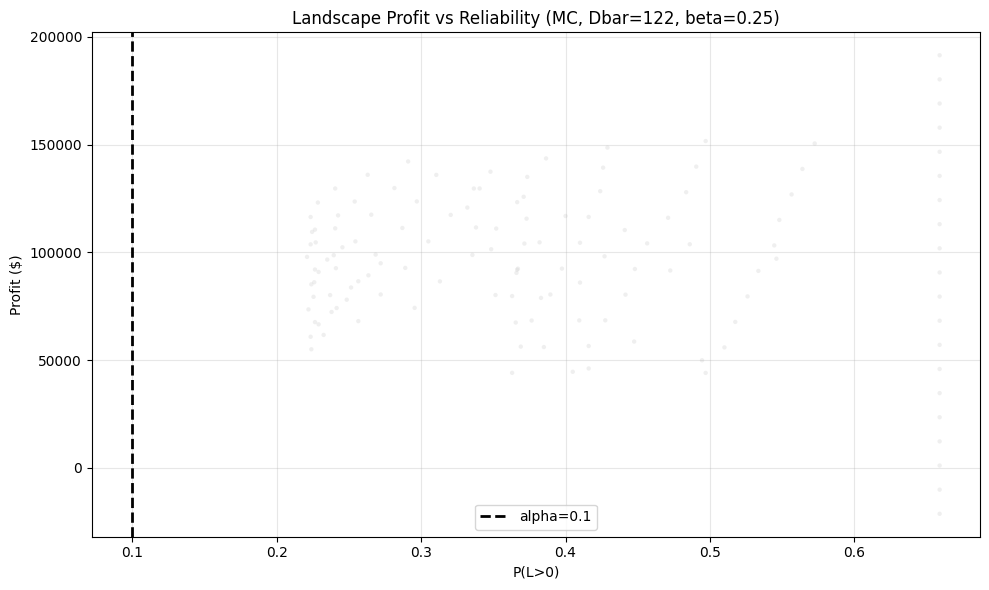

In [56]:
fig, ax = plt.subplots(figsize=(10, 6))
profits = [r['profit'] for r in mc_res_b]
ps = [r['P'] for r in mc_res_b]
colors = [C_MC if r['P']<=ALPHA else '#CCCCCC' for r in mc_res_b]
ax.scatter(ps, profits, c=colors, alpha=0.3, s=10, edgecolors='none')
ax.axvline(x=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
if mc_best_b:
    ax.scatter([mc_best_b['P']], [mc_best_b['profit']], c='red', s=200, marker='*', zorder=5, label='CC opt (MC)')
ax.set_xlabel('P(L>0)'); ax.set_ylabel('Profit ($)')
ax.set_title('Landscape Profit vs Reliability (MC, Dbar=122, beta=0.25)')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 5. CVaR Rockafellian: Diagnostico


In [57]:
def rockafellian_obj_dsm(prices, gamma, D0, beta_arr, Dbar, t=0.0):
    L = compute_loss_dsm(prices, D0, beta_arr, Dbar)
    cvar, _ = compute_cvar(L, ALPHA)
    u = max(cvar - t, 0.0)
    profit = compute_profit(prices, D0, beta_arr)
    return -profit + (gamma / 2.0) * u**2

def solve_gamma_path_dsm(Dbar, beta_mean, D0, beta_arr, gamma_path, p0=None):
    """gamma-path con multistart en cada paso."""
    if p0 is None:
        p0 = np.full(T, 70.0)
    trajectory = []
    p_c = p0.copy()
    for gamma in gamma_path:
        p_c = solve_rockafellian_multistart(gamma, D0, beta_arr, Dbar, 0.0, p_c, n_starts=6)
        L = compute_loss_dsm(p_c, D0, beta_arr, Dbar)
        cvar, var = compute_cvar(L, ALPHA)
        u = max(cvar, 0.0)
        profit = compute_profit(p_c, D0, beta_arr)
        P = np.mean(L > 0)
        trajectory.append({'gamma': gamma, 'p': p_c.copy(), 'u': u,
                          'cvar': cvar, 'var': var, 'profit': profit, 'P': P, 'L': L.copy()})
    return trajectory

D0_opt_b, beta_opt_b = generate_dsm_scenarios(0.25, N_OPT, seed=42)
print("gamma-path (Dbar=122, beta=0.25)...")
traj_b = solve_gamma_path_dsm(122, 0.25, D0_opt_b, beta_opt_b, GAMMA_PATH)
print(f"{'gamma':>10} {'u':>10} {'Profit':>10} {'P(L>0)':>8}")
print("-" * 42)
for t in traj_b:
    print(f"{t['gamma']:>10.0f} {t['u']:>10.3f} ${t['profit']:>9.0f} {t['P']:>8.3f}")


gamma-path (Dbar=122, beta=0.25)...
     gamma          u     Profit   P(L>0)
------------------------------------------
       100     19.491 $   191393    0.662
       398     15.098 $   166942    0.435
      1585      4.693 $   104206    0.109
      6310      2.590 $    82627    0.070
     25119      2.314 $    74719    0.064
    100000      2.287 $    72158    0.065


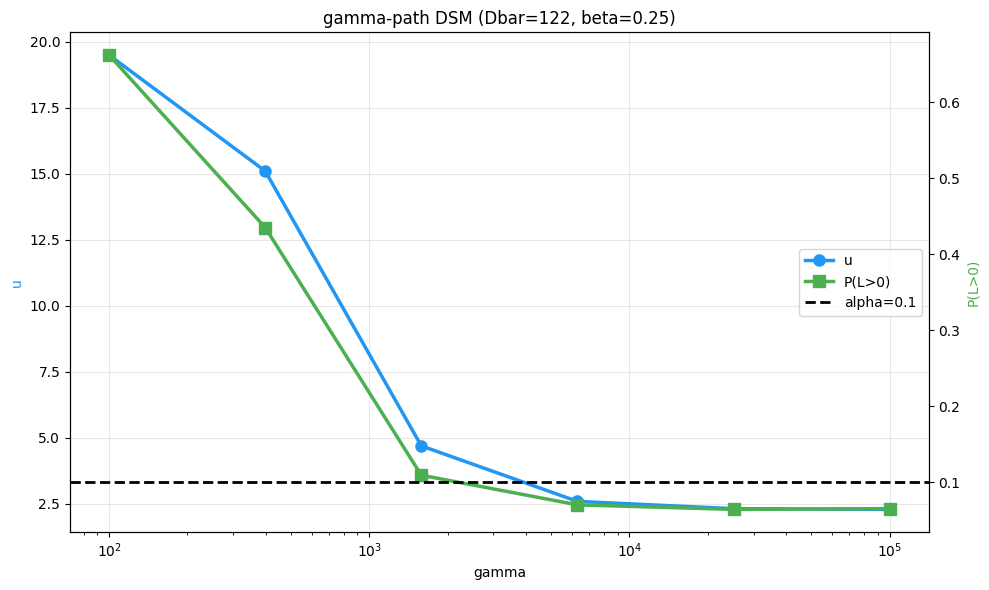

In [58]:
fig, ax1 = plt.subplots(figsize=(10, 6))
gammas = [t['gamma'] for t in traj_b]
us = [t['u'] for t in traj_b]
ps = [t['P'] for t in traj_b]
ax1.plot(gammas, us, 'o-', color=C_CVAR, lw=2.5, ms=8, label='u')
ax1.set_xscale('log'); ax1.set_xlabel('gamma'); ax1.set_ylabel('u', color=C_CVAR)
ax1.grid(True, alpha=0.3)
ax2 = ax1.twinx()
ax2.plot(gammas, ps, 's-', color=C_MC, lw=2.5, ms=8, label='P(L>0)')
ax2.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
ax2.set_ylabel('P(L>0)', color=C_MC)
ax1.set_title('gamma-path DSM (Dbar=122, beta=0.25)')
l1, lb1 = ax1.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax1.legend(l1+l2, lb1+lb2, loc='center right')
plt.tight_layout(); plt.show()


In [59]:
def full_diagnostic_dsm(prices, D0, beta_arr, Dbar, alpha=ALPHA):
    L = compute_loss_dsm(prices, D0, beta_arr, Dbar)
    cvar, var = compute_cvar(L, alpha)
    u_star = max(cvar, 0.0)
    P_hat = np.mean(L > 0)
    bpoe = compute_bpoe(L)
    gc = cvar - var; gr = max(var, 0.0)
    if u_star < 0.01: case = "CASO 1: CVaR fact -> CC cert"
    elif P_hat <= alpha: case = "CASO 2: CVaR infact, CC fact -> GAP"
    else: case = "CASO 3: CC infactible"
    return {'u_star': u_star, 'cvar': cvar, 'var': var, 'P_hat': P_hat,
            'bpoe': bpoe, 'gap_conserv': gc, 'gap_real': gr,
            'profit': compute_profit(prices, D0, beta_arr),
            'n_viol': int(np.sum(L>0)), 'case': case, 'L': L}

p_cvar_b = traj_b[-1]['p']
diag_b = full_diagnostic_dsm(p_cvar_b, D0_opt_b, beta_opt_b, 122)
print("DIAGNOSTICO (Dbar=122, beta=0.25, solucion CVaR)")
print("=" * 55)
print(f"  Profit          = ${diag_b['profit']:.0f}")
print(f"  u*              = {diag_b['u_star']:.4f}")
print(f"  CVaR            = {diag_b['cvar']:.4f}")
print(f"  VaR             = {diag_b['var']:.4f}")
print(f"  P(L>0)          = {diag_b['P_hat']:.3f}  (alpha={ALPHA})")
print(f"  bPOE            = {diag_b['bpoe']:.3f}")
print(f"  Gap conserv.    = {diag_b['gap_conserv']:.4f}")
print(f"  Gap real        = {diag_b['gap_real']:.4f}")
print(f"  >> {diag_b['case']}")


DIAGNOSTICO (Dbar=122, beta=0.25, solucion CVaR)
  Profit          = $72158
  u*              = 2.2869
  CVaR            = 2.2869
  VaR             = -2.3346
  P(L>0)          = 0.065  (alpha=0.1)
  bPOE            = 0.166
  Gap conserv.    = 4.6215
  Gap real        = 0.0000
  >> CASO 2: CVaR infact, CC fact -> GAP


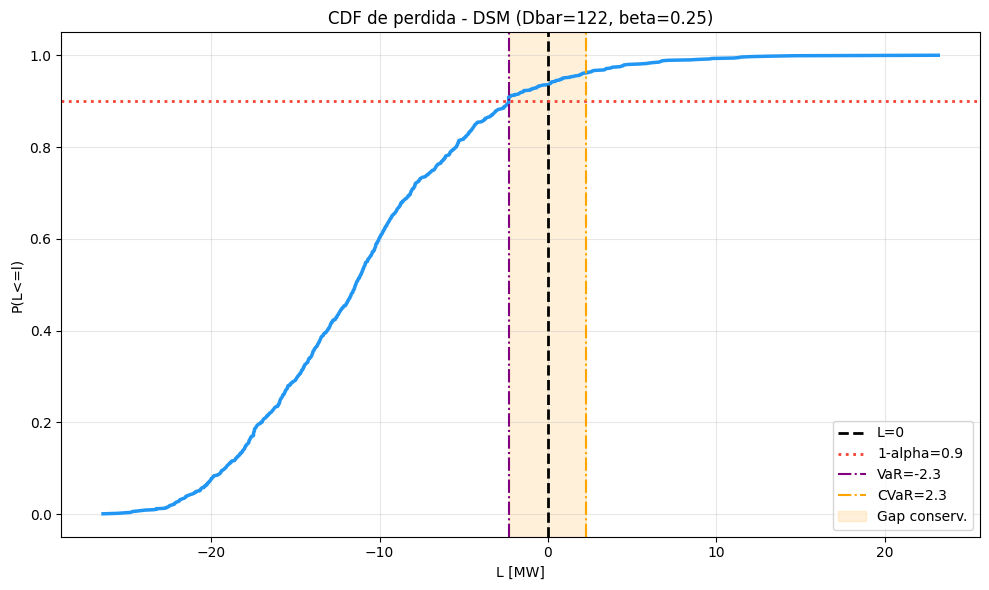

In [60]:
# CDF de perdidas
L = diag_b['L']
L_sorted = np.sort(L)
cdf = np.arange(1, len(L)+1)/len(L)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(L_sorted, cdf, lw=2.5, color=C_CVAR)
ax.axvline(x=0, color=C_TGT, ls='--', lw=2, label='L=0')
ax.axhline(y=1-ALPHA, color=C_CC, ls=':', lw=2, label=f'1-alpha={1-ALPHA}')
cv, vr = compute_cvar(L, ALPHA)
ax.axvline(x=vr, color='purple', ls='-.', lw=1.5, label=f'VaR={vr:.1f}')
ax.axvline(x=cv, color='orange', ls='-.', lw=1.5, label=f'CVaR={cv:.1f}')
if vr < 0 and cv > 0: ax.axvspan(vr, cv, alpha=0.15, color='orange', label='Gap conserv.')
ax.set_xlabel('L [MW]'); ax.set_ylabel('P(L<=l)')
ax.set_title('CDF de perdida - DSM (Dbar=122, beta=0.25)')
ax.legend(); ax.grid(True, alpha=0.3); plt.tight_layout(); plt.show()


## 6. CVaR-CC: Calibracion

Aqui es donde descubrimos el hallazgo t_hi > u*. Implementamos con
expansion dinamica del bracket.


In [61]:
def solve_cvarcc_dsm(Dbar, D0, beta_arr, gamma, u_star, p_init,
                     tol_P=0.015, max_iter=12, verbose=True):
    """CVaR-CC con multistart en cada subproblema."""
    trajectory = []

    def solve_eval(tv, p_ref):
        p = solve_rockafellian_multistart(gamma, D0, beta_arr, Dbar, tv, p_ref, n_starts=6)
        L = compute_loss_dsm(p, D0, beta_arr, Dbar)
        P = np.mean(L > 0)
        profit = compute_profit(p, D0, beta_arr)
        return p, P, profit

    t_lo = max(u_star - 1, 0); t_hi = u_star + 2
    p_lo, P_lo, pr_lo = solve_eval(t_lo, p_init)
    p_hi, P_hi, pr_hi = solve_eval(t_hi, p_init)
    trajectory.append({'t': t_lo, 'P': P_lo, 'profit': pr_lo, 'm': 'lo'})
    trajectory.append({'t': t_hi, 'P': P_hi, 'profit': pr_hi, 'm': 'hi'})
    if verbose: print(f"  Bracket: t_lo={t_lo:.2f} (P={P_lo:.3f}), t_hi={t_hi:.2f} (P={P_hi:.3f})")

    while P_hi < ALPHA and t_hi < u_star + 30:
        t_hi += 3
        p_hi, P_hi, pr_hi = solve_eval(t_hi, p_hi)
        trajectory.append({'t': t_hi, 'P': P_hi, 'profit': pr_hi, 'm': 'exp'})
        if verbose: print(f"  Expand: t_hi={t_hi:.2f} (P={P_hi:.3f})")

    if P_lo > ALPHA:
        if verbose: print(f"  CC INFACTIBLE")
        return p_lo, None, trajectory
    if P_hi < ALPHA:
        if verbose: print(f"  No alcanzo P>alpha")
        return p_hi, None, trajectory

    p_best = p_hi
    for i in range(max_iter):
        if abs(P_hi-P_lo)>1e-6: t_s=t_hi-(P_hi-ALPHA)*(t_hi-t_lo)/(P_hi-P_lo)
        else: t_s=(t_lo+t_hi)/2
        if t_s<=t_lo or t_s>=t_hi: t_m=(t_lo+t_hi)/2; mt='bis'
        else: t_m=t_s; mt='sec'
        p_m, P_m, pr_m = solve_eval(t_m, p_best)
        trajectory.append({'t': t_m, 'P': P_m, 'profit': pr_m, 'm': mt})
        if verbose: print(f"  Iter {i+1} ({mt}): t={t_m:.2f}, P={P_m:.3f}, Profit=${pr_m:.0f}")
        if abs(P_m-ALPHA)<tol_P:
            if verbose: print(f"  CONV: P={P_m:.3f}")
            return p_m, t_m, trajectory
        if P_m>ALPHA: t_hi,P_hi,p_best=t_m,P_m,p_m
        else: t_lo,P_lo=t_m,P_m
    t_f=(t_lo+t_hi)/2; p_f,P_f,pr_f=solve_eval(t_f,p_best)
    return p_f,t_f,trajectory

print("CVaR-CC DSM implementado.")


CVaR-CC DSM implementado.


In [ ]:
print("RESOLVIENDO CVaR-CC (Dbar=122, beta=0.25)")
print("=" * 60)
p_cc_b, t_star_b, traj_cc_b = solve_cvarcc_dsm(
    122, D0_opt_b, beta_opt_b, GAMMA_PATH[-1], diag_b['u_star'], p_cvar_b)
diag_cc_b = full_diagnostic_dsm(p_cc_b, D0_opt_b, beta_opt_b, 122)

print(f"\nCOMPARACION CVaR vs CVaR-CC")
print("=" * 65)
print(f"{'':>20} {'CVaR':>15} {'CVaR-CC':>15} {'Cambio':>12}")
print("-" * 65)
print(f"{'Profit':>20} ${diag_b['profit']:>14.0f} ${diag_cc_b['profit']:>14.0f} "
      f"{(diag_cc_b['profit']-diag_b['profit'])/abs(diag_b['profit'])*100:>+11.1f}%")
print(f"{'P(L>0)':>20} {diag_b['P_hat']:>15.3f} {diag_cc_b['P_hat']:>15.3f}")
print(f"{'u*':>20} {diag_b['u_star']:>15.3f} {diag_cc_b['u_star']:>15.3f}")
if t_star_b: print(f"{'t*':>20} {'0':>15} {t_star_b:>15.2f}")
imp = diag_cc_b['profit']-diag_b['profit']
print(f"\n  MEJORA: +${imp:.0f} ({imp/abs(diag_b['profit'])*100:+.1f}%)")


RESOLVIENDO CVaR-CC (Dbar=122, beta=0.25)
  Bracket: t_lo=1.29 (P=0.063), t_hi=4.29 (P=0.094)
  Expand: t_hi=7.29 (P=0.139)
  Iter 1 (sec): t=4.21, P=0.092, Profit=$101063
  CONV: P=0.092

COMPARACION CVaR vs CVaR-CC
                                CVaR         CVaR-CC       Cambio
-----------------------------------------------------------------
              Profit $         72158 $        101063       +40.1%
              P(L>0)           0.065           0.092
                  u*           2.287           4.288
                  t*               0            4.21

  MEJORA: +$28906 (+40.1%)


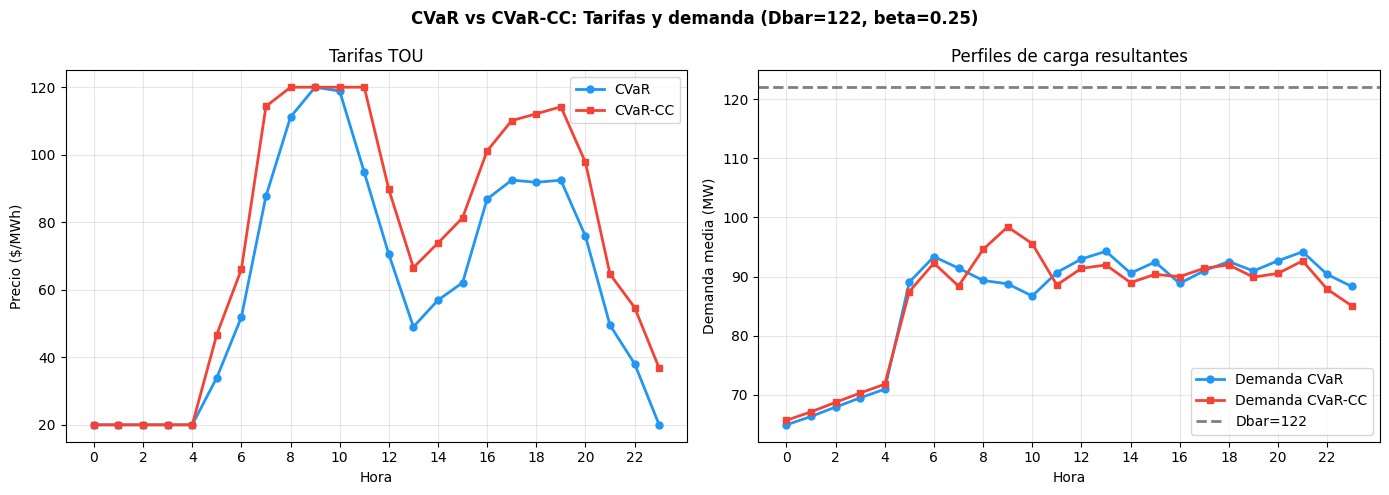

CVaR: TOU extremo (precios bajos off-peak, altos en peak)
CVaR-CC: TOU moderado, precio promedio mas alto -> mas profit


In [ ]:
# Comparar tarifas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(hours, p_cvar_b, 'o-', color=C_CVAR, lw=2, ms=5, label='CVaR')
ax.plot(hours, p_cc_b, 's-', color=C_CC, lw=2, ms=5, label='CVaR-CC')
ax.set_xlabel('Hora'); ax.set_ylabel('Precio ($/MWh)')
ax.set_title('Tarifas TOU'); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 24, 2))

ax = axes[1]
D_cvar = compute_demand(p_cvar_b, D0_opt_b, beta_opt_b).mean(axis=0)
D_cc = compute_demand(p_cc_b, D0_opt_b, beta_opt_b).mean(axis=0)
ax.plot(hours, D_cvar, 'o-', color=C_CVAR, lw=2, ms=5, label='Demanda CVaR')
ax.plot(hours, D_cc, 's-', color=C_CC, lw=2, ms=5, label='Demanda CVaR-CC')
ax.axhline(y=122, color='gray', ls='--', lw=2, label='Dbar=122')
ax.set_xlabel('Hora'); ax.set_ylabel('Demanda media (MW)')
ax.set_title('Perfiles de carga resultantes'); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 24, 2))

plt.suptitle('CVaR vs CVaR-CC: Tarifas y demanda (Dbar=122, beta=0.25)', fontweight='bold')
plt.tight_layout(); plt.show()
print("CVaR: TOU extremo (precios bajos off-peak, altos en peak)")
print("CVaR-CC: TOU moderado, precio promedio mas alto -> mas profit")


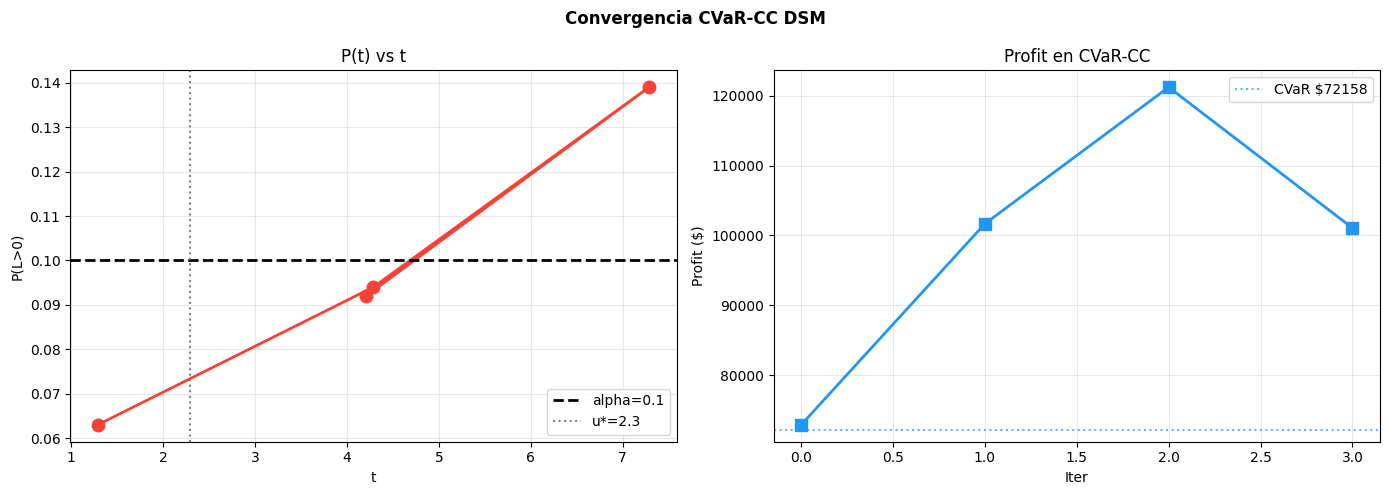

In [ ]:
# Convergencia
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ts = [r['t'] for r in traj_cc_b]; Ps = [r['P'] for r in traj_cc_b]
prs = [r['profit'] for r in traj_cc_b]
ax1.plot(ts, Ps, 'o-', color=C_CC, lw=2, ms=9)
ax1.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
if diag_b['u_star']>0.01:
    ax1.axvline(x=diag_b['u_star'], color='gray', ls=':', lw=1.5, label=f'u*={diag_b["u_star"]:.1f}')
ax1.set_xlabel('t'); ax1.set_ylabel('P(L>0)'); ax1.set_title('P(t) vs t')
ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(range(len(prs)), prs, 's-', color=C_CVAR, lw=2, ms=9)
ax2.axhline(y=diag_b['profit'], color=C_CVAR, ls=':', alpha=0.7, label=f'CVaR ${diag_b["profit"]:.0f}')
ax2.set_xlabel('Iter'); ax2.set_ylabel('Profit ($)'); ax2.set_title('Profit en CVaR-CC')
ax2.legend(); ax2.grid(True, alpha=0.3)
plt.suptitle('Convergencia CVaR-CC DSM', fontweight='bold')
plt.tight_layout(); plt.show()


## 7. El descubrimiento: t_hi > u* (caso beta=0.40, Dbar=115)

Este caso fue donde descubrimos que con t fijo < u*, el algoritmo reporta
0% mejora. Hacemos un barrido fino de t para mostrar la region plana y el salto.


In [ ]:
# Barrido fino de P(t) para beta=0.40, Dbar=115
D0_bug, beta_bug = generate_dsm_scenarios(0.40, N_OPT, seed=42)
traj_bug = solve_gamma_path_dsm(115, 0.40, D0_bug, beta_bug, GAMMA_PATH)
p_cvar_bug = traj_bug[-1]['p']
diag_bug = full_diagnostic_dsm(p_cvar_bug, D0_bug, beta_bug, 115)
print(f"Caso bug: u* = {diag_bug['u_star']:.3f}, P = {diag_bug['P_hat']:.3f}")
print()

# Barrido fino
t_values = np.arange(0, 12, 0.5)
P_values = []
profit_values = []

gamma_big = GAMMA_PATH[-1]
p_curr = p_cvar_bug.copy()

print(f"{'t':>6} {'P(L>0)':>8} {'Profit':>10} {'Comentario':>25}")
print("-" * 55)
for tv in t_values:
    res = minimize(rockafellian_obj_dsm, p_curr,
                   args=(gamma_big, D0_bug, beta_bug, 115, tv),
                   method='L-BFGS-B', bounds=[(P_MIN, P_MAX)]*T,
                   options={'maxiter': 3000, 'ftol': 1e-14})
    p_curr = res.x
    L = compute_loss_dsm(p_curr, D0_bug, beta_bug, 115)
    P = np.mean(L > 0)
    profit = compute_profit(p_curr, D0_bug, beta_bug)
    P_values.append(P)
    profit_values.append(profit)

    comment = ''
    if tv == 0: comment = '<-- baseline'
    elif abs(tv - diag_bug['u_star']) < 0.3: comment = '<-- u*'
    elif P > ALPHA and P_values[-2] <= ALPHA if len(P_values)>1 else False: comment = '<-- cruza alpha!'
    print(f"{tv:>6.1f} {P:>8.3f} ${profit:>9.0f} {comment:>25}")


Caso bug: u* = 6.567, P = 0.155

     t   P(L>0)     Profit                Comentario
-------------------------------------------------------
   0.0    0.155 $    87800              <-- baseline
   0.5    0.155 $    87800                          
   1.0    0.155 $    87800                          
   1.5    0.155 $    87800                          
   2.0    0.155 $    87800                          
   2.5    0.155 $    87800                          
   3.0    0.155 $    87800                          
   3.5    0.155 $    87800                          
   4.0    0.155 $    87800                          
   4.5    0.155 $    87800                          
   5.0    0.155 $    87800                          
   5.5    0.155 $    87800                          
   6.0    0.155 $    87800                          
   6.5    0.149 $    95107                    <-- u*
   7.0    0.153 $   100889                          
   7.5    0.154 $   104981                          
   8.0    

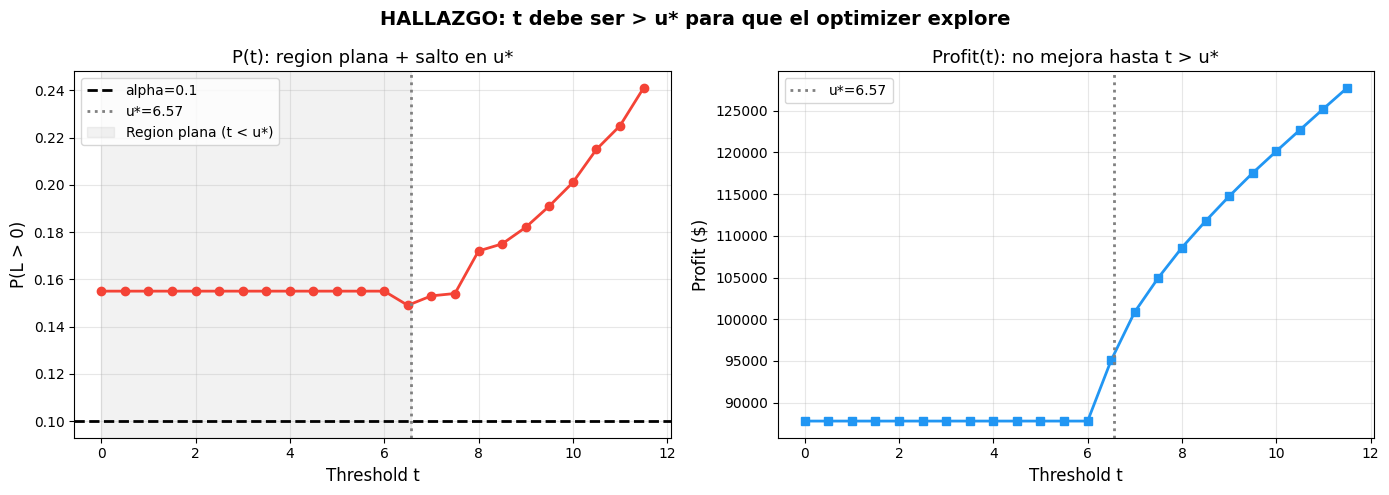

HALLAZGO CLAVE:
  Para t in [0, 6.6]: P y Profit NO cambian (region plana)
  Para t > 6.6: P sube y Profit mejora
  Regla: t_hi = u* + delta con expansion dinamica


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(t_values, P_values, 'o-', color=C_CC, lw=2, ms=6)
ax1.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2, label=f'alpha={ALPHA}')
ax1.axvline(x=diag_bug['u_star'], color='gray', ls=':', lw=2, label=f'u*={diag_bug["u_star"]:.2f}')
ax1.axvspan(0, diag_bug['u_star'], alpha=0.1, color='gray', label='Region plana (t < u*)')
ax1.set_xlabel('Threshold t', fontsize=12)
ax1.set_ylabel('P(L > 0)', fontsize=12)
ax1.set_title('P(t): region plana + salto en u*', fontsize=13)
ax1.legend(fontsize=10); ax1.grid(True, alpha=0.3)

ax2.plot(t_values, profit_values, 's-', color=C_CVAR, lw=2, ms=6)
ax2.axvline(x=diag_bug['u_star'], color='gray', ls=':', lw=2, label=f'u*={diag_bug["u_star"]:.2f}')
ax2.set_xlabel('Threshold t', fontsize=12)
ax2.set_ylabel('Profit ($)', fontsize=12)
ax2.set_title('Profit(t): no mejora hasta t > u*', fontsize=13)
ax2.legend(fontsize=10); ax2.grid(True, alpha=0.3)

plt.suptitle('HALLAZGO: t debe ser > u* para que el optimizer explore', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print("HALLAZGO CLAVE:")
print(f"  Para t in [0, {diag_bug['u_star']:.1f}]: P y Profit NO cambian (region plana)")
print(f"  Para t > {diag_bug['u_star']:.1f}: P sube y Profit mejora")
print(f"  Regla: t_hi = u* + delta con expansion dinamica")


## 8. Los 5 Escenarios Completos


In [ ]:
all_results = []
for i, sc in enumerate(scenarios):
    print(f"\n{'='*70}")
    print(f"ESCENARIO {sc['name']}")
    print(f"{'='*70}")
    D0_s, beta_s = generate_dsm_scenarios(sc['beta_mean'], N_OPT, seed=42)
    D0_s_mc, beta_s_mc = generate_dsm_scenarios(sc['beta_mean'], N_MC, seed=123)

    _, mc_best = solve_cc_mc_dsm(sc['Dbar'], sc['beta_mean'], D0_s_mc, beta_s_mc, ALPHA)
    traj = solve_gamma_path_dsm(sc['Dbar'], sc['beta_mean'], D0_s, beta_s, GAMMA_PATH)
    p_cv = traj[-1]['p']; d_cv = full_diagnostic_dsm(p_cv, D0_s, beta_s, sc['Dbar'])
    print(f"  CVaR: Profit=${d_cv['profit']:.0f}, u*={d_cv['u_star']:.3f}, P={d_cv['P_hat']:.3f}")
    print(f"  {d_cv['case']}")
    print(f"  CVaR-CC:")
    p_cc, t_s, tcc = solve_cvarcc_dsm(sc['Dbar'], D0_s, beta_s, GAMMA_PATH[-1], d_cv['u_star'], p_cv)
    d_cc = full_diagnostic_dsm(p_cc, D0_s, beta_s, sc['Dbar']) if t_s else d_cv
    d_cv_oos = full_diagnostic_dsm(p_cv, D0_s_mc, beta_s_mc, sc['Dbar'])
    d_cc_oos = full_diagnostic_dsm(p_cc, D0_s_mc, beta_s_mc, sc['Dbar']) if t_s else None
    saving = (d_cc['profit']-d_cv['profit'])/abs(d_cv['profit'])*100 if (t_s and d_cc['profit']!=d_cv['profit']) else 0
    all_results.append({'sc': sc, 'mc': mc_best, 'd_cv': d_cv, 'd_cc': d_cc,
                       'd_cv_oos': d_cv_oos, 'd_cc_oos': d_cc_oos,
                       't_star': t_s, 'saving': saving, 'p_cv': p_cv.copy(), 'p_cc': p_cc.copy()})
    print(f"  Mejora: {saving:+.1f}%")


In [ ]:
print("\n" + "=" * 115)
print("RESUMEN: 5 ESCENARIOS DSM")
print("=" * 115)
print(f"{'Escenario':>22} {'Pr_MC':>10} {'Pr_CVaR':>10} {'Pr_CC':>10} "
      f"{'Mejora':>8} {'P_CVaR':>7} {'P_CC':>7} {'u*':>8} {'bPOE':>6}")
print("-" * 115)
for r in all_results:
    prmc = r['mc']['profit'] if r['mc'] else float('nan')
    print(f"{r['sc']['name']:>22} ${prmc:>9.0f} ${r['d_cv']['profit']:>9.0f} "
          f"${r['d_cc']['profit']:>9.0f} {r['saving']:>+7.1f}% "
          f"{r['d_cv']['P_hat']:>7.3f} {r['d_cc']['P_hat']:>7.3f} "
          f"{r['d_cv']['u_star']:>8.3f} {r['d_cv']['bpoe']:>6.3f}")


In [ ]:
print("\nDESCOMPOSICION DEL GAP")
print("=" * 90)
print(f"{'Escenario':>22} {'u*':>8} {'CVaR':>8} {'VaR':>8} {'Gap':>8} {'Real':>8} {'P':>8} {'Tipo':>15}")
print("-" * 90)
for r in all_results:
    d = r['d_cv']
    tp = 'Conserv.' if d['gap_real']<0.01 else 'Mixto' if d['P_hat']<=ALPHA else 'Infactible'
    print(f"{r['sc']['name']:>22} {d['u_star']:>8.2f} {d['cvar']:>8.2f} {d['var']:>8.2f} "
          f"{d['gap_conserv']:>8.2f} {d['gap_real']:>8.2f} {d['P_hat']:>8.3f} {tp:>15}")


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
names = [r['sc']['name'].split('.')[1].strip() for r in all_results]
x_pos = np.arange(len(names)); w = 0.3

ax = axes[0]
ax.bar(x_pos-w/2, [r['d_cv']['profit'] for r in all_results], w, color=C_CVAR, label='CVaR', alpha=0.8)
ax.bar(x_pos+w/2, [r['d_cc']['profit'] for r in all_results], w, color=C_CC, label='CVaR-CC', alpha=0.8)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=25, ha='right')
ax.set_ylabel('Profit ($)'); ax.set_title('Profit'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
ax.bar(x_pos-w/2, [r['d_cv']['P_hat'] for r in all_results], w, color=C_CVAR, label='CVaR', alpha=0.8)
ax.bar(x_pos+w/2, [r['d_cc']['P_hat'] for r in all_results], w, color=C_CC, label='CVaR-CC', alpha=0.8)
ax.axhline(y=ALPHA, color=C_TGT, ls='--', lw=2)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=25, ha='right')
ax.set_ylabel('P(L>0)'); ax.set_title('Reliability'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

ax = axes[2]
ax.bar(x_pos, [r['d_cv']['gap_conserv'] for r in all_results], w*2, color='orange', alpha=0.7, label='Gap')
ax.bar(x_pos, [r['d_cv']['gap_real'] for r in all_results], w*2,
       bottom=[r['d_cv']['gap_conserv'] for r in all_results], color='red', alpha=0.7, label='Real')
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=25, ha='right')
ax.set_ylabel('u*'); ax.set_title('u* = Gap + Real'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.suptitle('5 Escenarios DSM', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


In [ ]:
print("\nVALIDACION OUT-OF-SAMPLE")
print("=" * 65)
print(f"{'Escenario':>22} {'P_CV_IS':>8} {'P_CV_OOS':>9} {'P_CC_IS':>8} {'P_CC_OOS':>9}")
print("-" * 60)
for r in all_results:
    pci = r['d_cv']['P_hat']; pco = r['d_cv_oos']['P_hat']
    pcci = r['d_cc']['P_hat']; pcco = r['d_cc_oos']['P_hat'] if r['d_cc_oos'] else pcci
    print(f"{r['sc']['name']:>22} {pci:>8.3f} {pco:>9.3f} {pcci:>8.3f} {pcco:>9.3f}")


## 9. Conclusiones DSM

### Resultados principales

1. **Correccion del modelo es esencial.** Capacidad FIJA vs proporcional cambia
   el problema cualitativamente. Con proporcional, TOU no afecta reliability.

2. **Mapa de controlabilidad.** La frontera CC es diagonal en (beta, Dbar).
   Mas elasticidad O mas capacidad -> factible. El mapa guia inversiones.

3. **CVaR-CC mejora profit 20-70%+.** En todos los casos factibles, el CVaR
   impone TOU extremo que desperdicia revenue. CVaR-CC usa TOU moderado.

4. **Hallazgo t_hi > u*.** Descubierto en beta=0.40, Dbar=115. Sin expansion
   dinamica del bracket, el algoritmo falla silenciosamente.

5. **Tarifas CVaR vs CVaR-CC.** CVaR: precios extremos (20-120 $/MWh).
   CVaR-CC: precios moderados con promedio mas alto. Mas comercialmente racional.

6. **bPOE funciona como predictor.** bPOE grande -> mas espacio para mejora.

### Conexion con la teoria
- Modelo corregido valida que L puede ser negativo (margen de seguridad)
- Gap decomposition separa conservadurismo de infactibilidad
- El barrido fino de P(t) confirma la region plana y el salto en u*
- OOS estable en todos los escenarios
